# Hanle Published AWS Wind Data Analysis

This notebook analyzes the sample AWS (Automatic Weather Station) raw log data for the Hanle site. It handles:
- Parsing the raw meteorological serial log format.
- Correcting the midnight hour rollover formatting bug.
- Analyzing the systematic clock offset between the sensor and logging server.
- Reconstructing and plotting the wind speeds, wind directions, and rolling wind gusts.
- Generating polar scatter wind roses for the entire dataset and dynamically per month.

In [1]:
import os
import glob
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.cm as cm

# Set plot styling
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
%matplotlib inline

## 1. Raw Telemetry Log Parser

We define functions to extract the serial telemetry payloads, correct the midnight hour formatting bug (where the hour is reported as `24` for the first minute of the day), and load the text log files.

In [2]:
def parse_logged_string(line):
    # Regex to isolate the raw serial string between `<013>AA` and `<013><010>`
    match = re.search(r'\*\*\* Logged string = "<013>(AA,.*?)<013><010>" \*\*\*', line)
    if match:
        payload = match.group(1)
        return payload.split(',')
    return None

def parse_sensor_datetime(date_str, time_str):
    # Correct the midnight rollover formatting quirk
    if time_str.startswith("24:"):
        time_str = "00:" + time_str[3:]
    return pd.to_datetime(date_str + ' ' + time_str)

def load_hanle_logs(file_paths):
    all_records = []
    for fp in file_paths:
        with open(fp, 'r', errors='ignore') as f:
            for line in f:
                # Capture the log server clock (at the start of each log line)
                log_match = re.match(r'^(\d{4}/\d{2}/\d{2} \d{2}:\d{2}:\d{2}\.\d{3})', line)
                parts = parse_logged_string(line)
                if parts and len(parts) == 13:
                    log_time_str = log_match.group(1)
                    log_dt = pd.to_datetime(log_time_str)
                    
                    try:
                        sensor_dt = parse_sensor_datetime(parts[1], parts[2])
                        temp = float(parts[3])
                        # col_4 is empty ****** placeholder, col_5 is relative humidity
                        rh = pd.to_numeric(parts[5].replace('******', ''), errors='coerce')
                        wind_speed = float(parts[6])
                        wind_direction = float(parts[7])
                        voltage = float(parts[9])
                        current = float(parts[10])
                        
                        all_records.append({
                            'log_datetime': log_dt,
                            'sensor_datetime': sensor_dt,
                            'temperature': temp,
                            'relative_humidity': rh,
                            'wind_speed': wind_speed,
                            'wind_direction': wind_direction,
                            'system_voltage': voltage,
                            'system_current': current
                        })
                    except Exception as e:
                        pass
                        
    df = pd.DataFrame(all_records)
    df = df.sort_values('sensor_datetime').reset_index(drop=True)
    return df

## 2. Load the Sample Datasets

We read the two sample text log files from the raw Hanle directory and display a preview.

In [3]:
data_dir = r"../../data/raw/hanle_published"
file_paths = glob.glob(os.path.join(data_dir, "*_MetsSerServr.txt"))
print(f"Found {len(file_paths)} files:", [os.path.basename(f) for f in file_paths])

df = load_hanle_logs(file_paths)
print(f"Loaded {len(df):,} total records.")
df.head()

Found 2 files: ['20200101_MetsSerServr.txt', '20200104_MetsSerServr.txt']


Loaded 26,017 total records.


,log_datetime,sensor_datetime,temperature,relative_humidity,wind_speed,wind_direction,system_voltage,system_current
0,2020-01-01 17:19:31.562,2020-01-01 17:43:52,-11.5,18.6,15.6,214.0,53.10,-0.30
1,2020-01-01 17:19:35.468,2020-01-01 17:43:57,-11.5,18.7,15.3,200.0,53.41,-0.27
2,2020-01-01 17:19:40.468,2020-01-01 17:44:02,-11.5,18.7,17.2,211.0,53.08,-0.30
3,2020-01-01 17:19:45.421,2020-01-01 17:44:07,-11.5,18.7,16.8,211.0,53.43,-0.27
4,2020-01-01 17:22:06.375,2020-01-01 17:46:27,-11.5,18.6,15.2,223.0,53.45,-0.26


## 3. General Statistics and Clock Offsets

We review the ranges of our parsed values and verify the systematic offset of the internal AWS clock relative to the logging PC.

In [4]:
print("=== Basic Stats ===")
print(df[['temperature', 'relative_humidity', 'wind_speed', 'wind_direction', 'system_voltage', 'system_current']].describe())

df['clock_offset_sec'] = (df['sensor_datetime'] - df['log_datetime']).dt.total_seconds()
print("\n=== Clock Offset (Sensor - Log) ===")
print(f"  Mean Offset: {df['clock_offset_sec'].mean():.2f} seconds ({df['clock_offset_sec'].mean()/60.0:.2f} minutes)")
print(f"  Offset Std Dev: {df['clock_offset_sec'].std():.4f} seconds")

=== Basic Stats ===
        temperature  relative_humidity    wind_speed  wind_direction  \
count  26017.000000       26017.000000  26017.000000    26017.000000   
mean     -14.716597          30.101511      5.435719      209.862859   
std        1.694467           4.286437      5.020662       51.194063   
min      -18.400000          18.300000      0.000000        0.000000   
25%      -16.100000          27.500000      1.300000      191.000000   
50%      -14.700000          30.400000      3.100000      223.000000   
75%      -13.000000          33.600000      9.800000      234.000000   
max      -11.500000          40.500000     21.700000      358.000000   

       system_voltage  system_current  
count    26017.000000    26017.000000  
mean        53.235902       -0.274966  
std          0.188550        0.036194  
min         52.830000       -0.310000  
25%         53.060000       -0.300000  
50%         53.270000       -0.280000  
75%         53.400000       -0.260000  
max        

## 4. Time Series Plots (Wind Speed, Wind Gusts & Wind Direction)

Since the raw log data has a 5-second sampling frequency, it is a highly detailed high-frequency series. We plot wind speeds, rolling 10-minute maximums as a proxy for **wind gusts**, and wind directions.

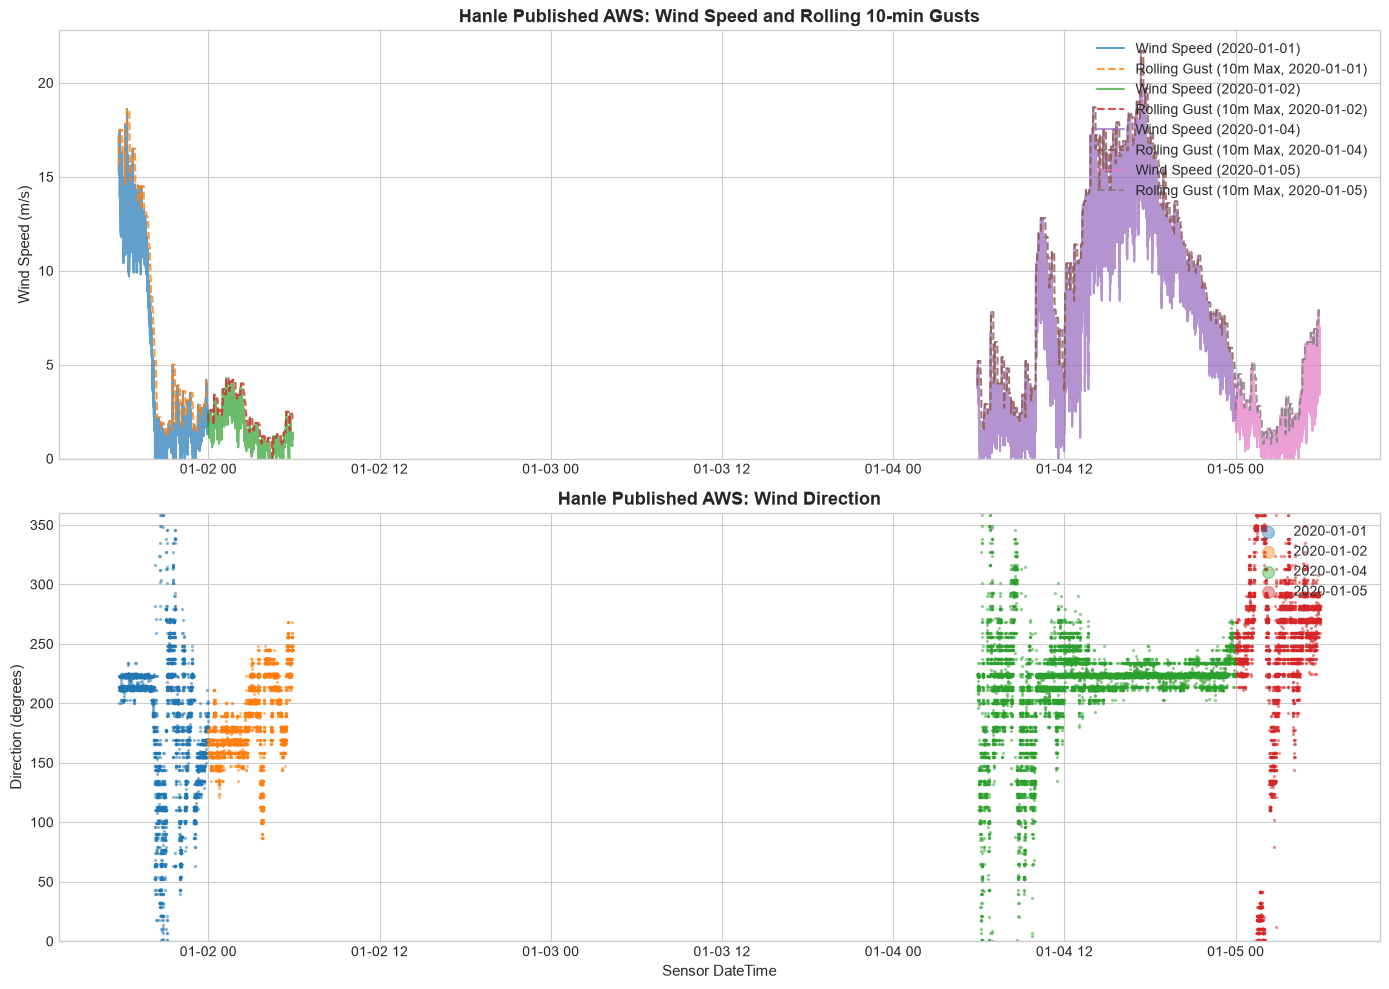

In [5]:
fig, axes = plt.subplots(2, 1, figsize=(14, 10), sharex=False)

# Group by date to plot individual segments clearly
df['day'] = df['sensor_datetime'].dt.date
unique_days = sorted(df['day'].unique())

for day in unique_days:
    day_df = df[df['day'] == day]
    if len(day_df) < 100:
        continue
    
    # 1. Wind Speed and rolling gust (10-minute maximum)
    axes[0].plot(day_df['sensor_datetime'], day_df['wind_speed'], label=f"Wind Speed ({day})", alpha=0.7)
    rolling_gust = day_df.rolling('10min', on='sensor_datetime')['wind_speed'].max()
    axes[0].plot(day_df['sensor_datetime'], rolling_gust, label=f"Rolling Gust (10m Max, {day})", linestyle='--', alpha=0.8)
    
    # 2. Wind Direction
    axes[1].scatter(day_df['sensor_datetime'], day_df['wind_direction'], label=f"{day}", s=2, alpha=0.4)

axes[0].set_title("Hanle Published AWS: Wind Speed and Rolling 10-min Gusts", fontsize=13, fontweight='bold')
axes[0].set_ylabel("Wind Speed (m/s)", fontsize=11)
axes[0].legend(loc='upper right')
axes[0].set_ylim(bottom=0)

axes[1].set_title("Hanle Published AWS: Wind Direction", fontsize=13, fontweight='bold')
axes[1].set_ylabel("Direction (degrees)", fontsize=11)
axes[1].set_xlabel("Sensor DateTime", fontsize=11)
axes[1].set_ylim(0, 360)
axes[1].legend(loc='upper right', markerscale=6)

plt.tight_layout()
plt.show()

## 5. Polar Scatter Wind Roses

We define a function to plot meteorological wind roses (where North is at 0° and angles increase clockwise) using polar coordinates, then plot the total and monthly wind patterns (grouped dynamically).

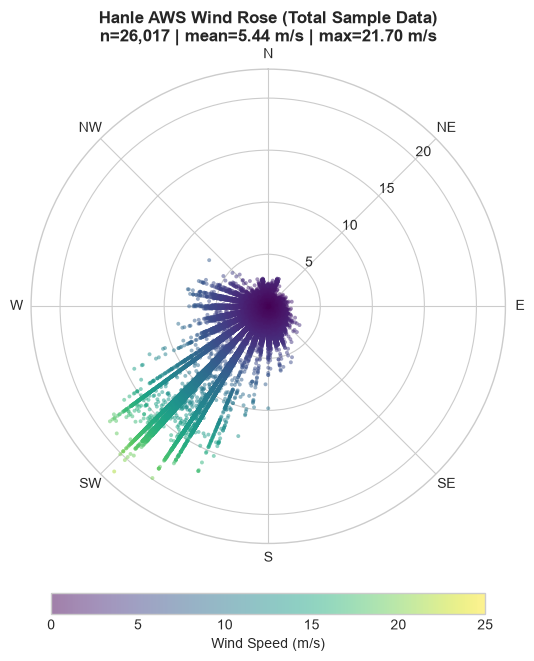

In [6]:
def plot_polar_wind_rose(speeds, directions, title):
    fig, ax = plt.subplots(figsize=(8, 8), subplot_kw={'polar': True})
    
    theta = np.radians(directions)
    sc = ax.scatter(theta, speeds, c=speeds, cmap='viridis', vmin=0, vmax=25.0, s=8, alpha=0.5, edgecolors='none')
    
    ax.set_theta_zero_location("N")
    ax.set_theta_direction(-1)  # Clockwise
    
    ax.set_thetagrids([0, 45, 90, 135, 180, 225, 270, 315], ['N', 'NE', 'E', 'SE', 'S', 'SW', 'W', 'NW'])
    ax.set_rlabel_position(45)
    
    mean_val = np.mean(speeds)
    max_val = np.max(speeds)
    ax.set_title(f"{title}\nn={len(speeds):,} | mean={mean_val:.2f} m/s | max={max_val:.2f} m/s", 
                 pad=20, fontsize=12, fontweight='bold')
    
    cbar = fig.colorbar(sc, ax=ax, orientation='horizontal', pad=0.08, shrink=0.7)
    cbar.set_label("Wind Speed (m/s)", fontsize=10)
    plt.show()

# Total Wind Rose
plot_polar_wind_rose(df['wind_speed'], df['wind_direction'], "Hanle AWS Wind Rose (Total Sample Data)")

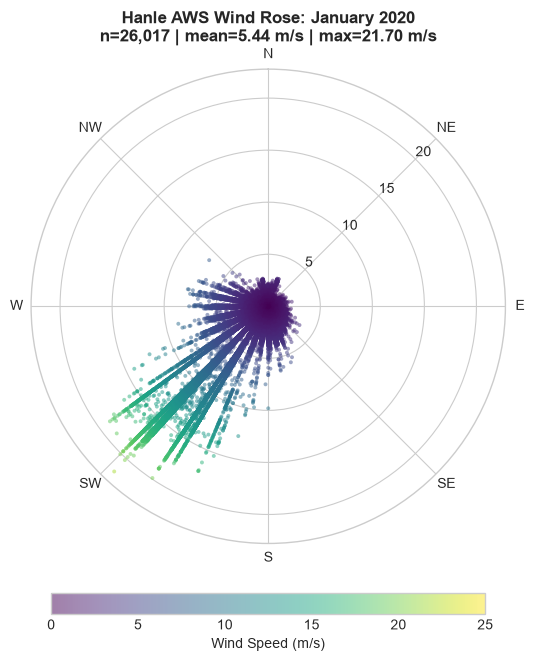

In [7]:
# Monthly Wind Roses (grouped dynamically by year and month)
df['year_month'] = df['sensor_datetime'].dt.to_period('M')
unique_months = sorted(df['year_month'].unique())

for ym in unique_months:
    month_df = df[df['year_month'] == ym]
    month_name = ym.strftime('%B %Y')
    plot_polar_wind_rose(month_df['wind_speed'], month_df['wind_direction'], f"Hanle AWS Wind Rose: {month_name}")

## 6. Diurnal Wind Profiles

We calculate the mean and standard deviation of wind speeds for each hour of the day (based on the sensor clock) to capture the diurnal variation.

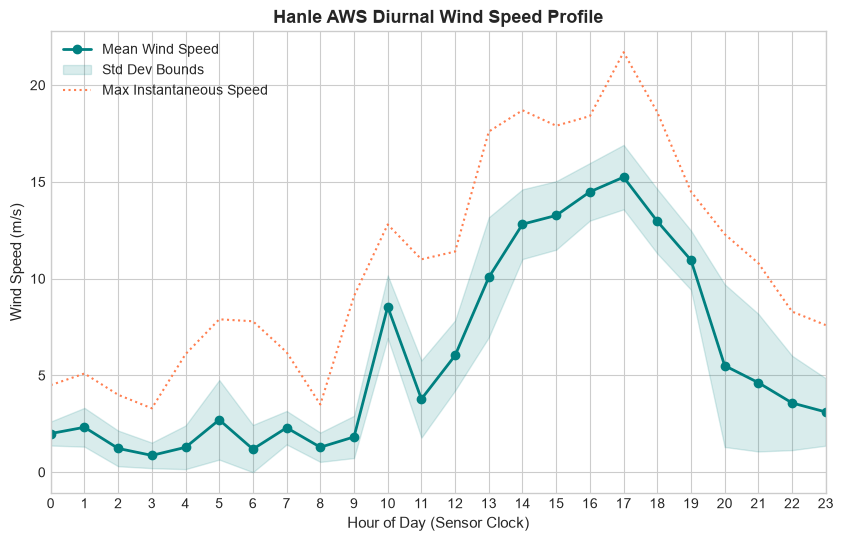

In [8]:
df['hour'] = df['sensor_datetime'].dt.hour
diurnal_stats = df.groupby('hour')['wind_speed'].agg(['mean', 'std', 'max'])

plt.figure(figsize=(10, 6))
plt.plot(diurnal_stats.index, diurnal_stats['mean'], marker='o', color='teal', linewidth=2, label='Mean Wind Speed')
plt.fill_between(diurnal_stats.index, 
                 np.maximum(0, diurnal_stats['mean'] - diurnal_stats['std']), 
                 diurnal_stats['mean'] + diurnal_stats['std'], 
                 color='teal', alpha=0.15, label='Std Dev Bounds')
plt.plot(diurnal_stats.index, diurnal_stats['max'], linestyle=':', color='coral', label='Max Instantaneous Speed')

plt.title("Hanle AWS Diurnal Wind Speed Profile", fontsize=13, fontweight='bold')
plt.xlabel("Hour of Day (Sensor Clock)", fontsize=11)
plt.ylabel("Wind Speed (m/s)", fontsize=11)
plt.xticks(range(24))
plt.xlim(0, 23)
plt.legend()
plt.show()